Generazione numeri random che seguono una legge binomiale(preso e copiato dalla lezione del 21-10-24)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multinomial

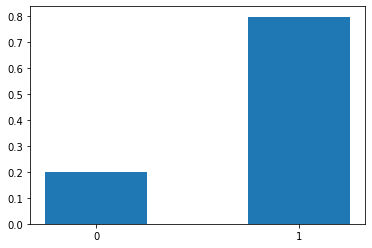

In [2]:
#Simuliamo il lancio di una moneta. p è la probabilità che esca testa, n il numero di lanci
p = 0.2
n = 1000

#La moneta potrebbe non essere equilibrata, generiamo un vettore di n numeri random tra 0 e 1
prove = np.random.rand(n)

#Ogni volta che un elemento è minore p, vuol dire che è uscita testa
#Per fare questa cosa utilizziamo il comando true, ovvero passiamo una condizione come 
#indice del vettore, otterremo come risultato un vettore con i soli elementi che 
#verificano la condizione

testa = prove[prove < p]
#print(testa)

#Dato che testa contiene tutti gli elementi < p, la sua lunghezza sarà il numero di volte 
#in cui è uscito testa
n_testa = testa.size

#Il numero di volte in cui è uscito croce sarà il numero totale di lanci meno le volte in cui 
#è uscita croce
n_croce = n - n_testa

#Plottiamo usando plt.bar
plt.xticks([0,1])
plt.bar([0,1], [n_testa/n, n_croce/n], width=0.5, align='center')
plt.show()

Generazione numeri random che seguono una legge Multinomiale (preso e copiato dalla lezione del 21-10-24)

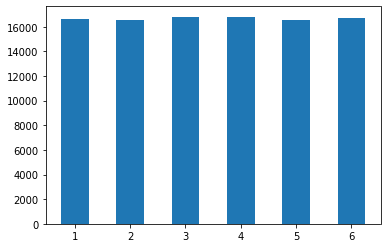

In [4]:
#Simuliamo n lanci del dado
n = 100000

#Se assumiamo che il dado sia equilibrato possiamo generare un vettore di n elementi con 
#valori random tra 1 e 6
dado = np.random.randint(1, 7, n) 

#Voglio sapere la frequenza con cui compare ogni numero estratto. Posso usare np.unique
#che restituisce una matrice: la prima riga contiene i numeri che compaiono in dado,
#la seconda riga la frequenza con cui questi compaiono.
F = np.unique(dado, return_counts=True)

#print(F)
#plotto l'istogramma dei risultati con le relative frequenze
plt.bar(F[0], F[1], width=0.5, align='center')
plt.show()

Generazione numeri random che seguono una legge Multinomiale (secondo la lezione del 16-12-24)

In [5]:
#Simuliamo n lanci del dado
n = 10000

#Se assumiamo che il dado sia equilibrato possiamo generare un vettore di n elementi con 
#valori random tra 1 e 6
#p1 = 1./6
#p2 = 1./6
#p3 = 1./6
#p4 = 1./6
#p5 = 1./6
#p6 = 1./6
#p = np.array([p1, p2, p3, p4, p5, p6])

p1 = 1./3
p2 = (1.-p1)/5

p = np.array([p1, p2, p2, p2, p2, p2])

F_i = np.cumsum(p)

prove = np.random.rand(n)

Ovviamente potete usare un if o uno switch, ma vediamo di farlo più "pythonesco".
Vi ricordo che np.where funziona che controlla se gli elementi di un array soddisfano una data condizione e sostitusce agli elementi che soddisfani questa condizione il secondo argomento e agli elementi che non la soddisfano il terzo argomento


[0.14825867 0.80492914 0.41474311 ... 0.60956873 0.41744422 0.48033751]
[1 5 2 ... 4 2 3]


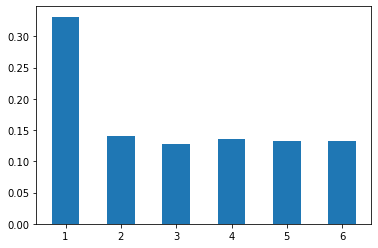

In [6]:
#dado = np.where(prove < F_i[0], 1, 0)

#for i in range(1, len(p)):
#    dado = np.where((prove < F_i[i])&(prove >=F_i[i-1]), i+1, dado) 

dado = np.sum(prove[:, None] >= F_i[:-1], axis=1) + 1
    
#Voglio sapere la frequenza con cui compare ogni numero estratto. Posso usare np.unique
#che restituisce una matrice: la prima riga contiene i numeri che compaiono in dado,
#la seconda riga la frequenza con cui questi compaiono.
F = np.unique(dado, return_counts=True)

print(prove)
print(dado)

#print(F)
#plotto l'istogramma dei risultati con le relative frequenze
plt.bar(F[0], F[1]/n, width=0.5, align='center')
#plt.plot(F[0], multinomial.pmf(n, p))
plt.show()